# Module 8 Lab 2: Textbook Problem 9.1, AI-Assisted (Clustering)
**Course:** CS 82A Introduction to Data Science  
**Name:** Ramisha Tasfia  
**Repo URL:** https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module8/module8_lab2.ipynb

## Load the data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Colab upload (does nothing outside Colab)
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

df = pd.read_csv("lifecyclesavings.csv")
df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


## Baseline by hand (no AI)

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the savings dataset
df = pd.read_csv("lifecyclesavings.csv")

# Display dataset shape
print("Dataset Shape:")
print(df.shape)

# Check missing values
print("\nMissing Values per Column:")
print(df.isnull().sum())

# Calculate the mean of each numerical column
print("\nMean of Each Column:")
print(df.mean(numeric_only=True).round(2))

Dataset Shape:
(50, 6)

Missing Values per Column:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Mean of Each Column:
sr          9.67
pop15      35.09
pop75       2.29
dpi      1106.76
ddpi        3.76
dtype: float64


## Prompt Log
**AI assistant used:** Claude (claude.ai)

### Prompt 1 (full text, Lab 1 template filled in)
```
You are helping with exploratory data analysis.
My CSV has columns: Contry (str), sr (float64), pop15 (float64), pop75 (float64), dpi (float64), ddpi (float64). Each row is one country (50 rows).
Write Python using pandas, scikit-learn, scipy, and seaborn to:
(1) cluster the countries into groups by their savings behavior using agglomerative (hierarchical) clustering,
(2) show the cluster means for each column,
(3) produce one labeled chart of the result.
Explain each step in comments.
```

**Other AI interactions this session:** I pasted the lab instructions, the textbook problem, and lifecyclesavings.csv into Claude and asked it to generate the clustering code.

### Fixes after running
None needed, code ran without errors.

## AI-generated clustering code (Claude), run as returned

In [3]:
# AI CODE 1: standardize the variables
# dpi is in the hundreds or thousands while the other columns are small,
# so scale every column to mean 0 and standard deviation 1 before clustering
from sklearn.preprocessing import StandardScaler

features = ["sr", "pop15", "pop75", "dpi", "ddpi"]
X = StandardScaler().fit_transform(df[features])
X[:3].round(2)

array([[ 0.4 , -0.63,  0.45,  1.25, -0.31],
       [ 0.54, -1.3 ,  1.66,  0.41,  0.06],
       [ 0.79, -1.25,  1.67,  1.02,  0.02]])

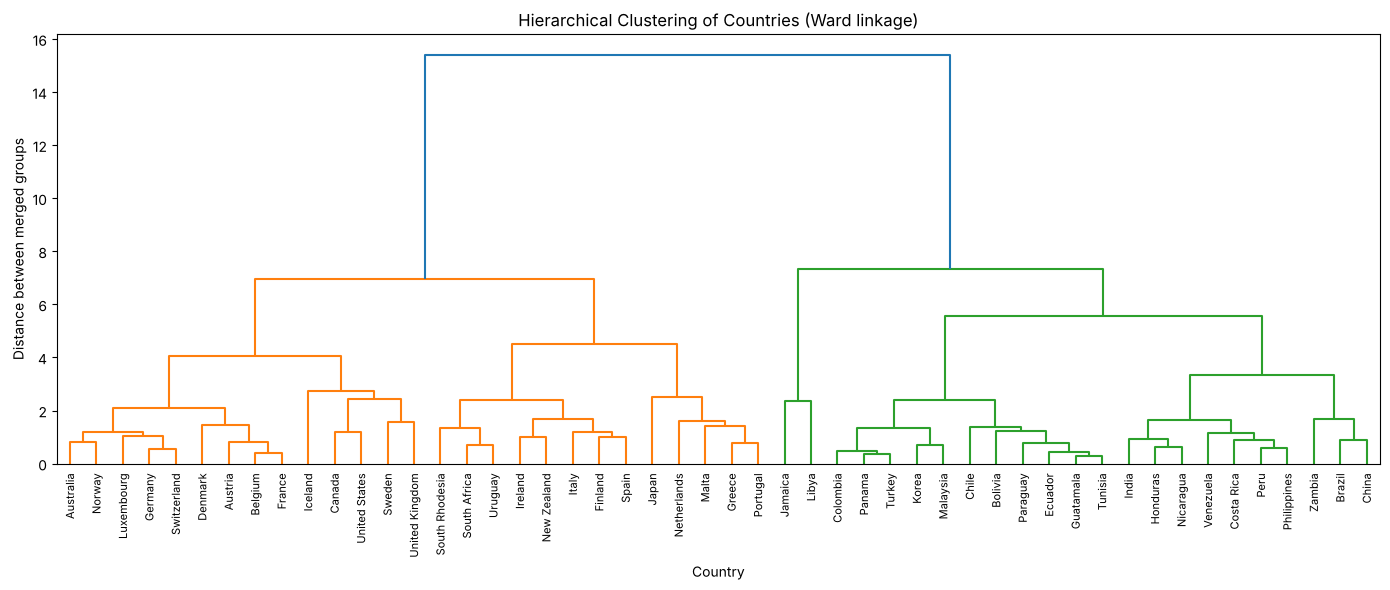

In [4]:
# AI CODE 2: agglomerative (hierarchical) clustering with Ward linkage
# Ward merges the two groups that increase within-group variance the least
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X, method="ward")

# Dendrogram: each leaf is a country, branch height is how different groups are
plt.figure(figsize=(14, 6))
dendrogram(Z, labels=df["Contry"].values, leaf_rotation=90)
plt.title("Hierarchical Clustering of Countries (Ward linkage)")
plt.xlabel("Country")
plt.ylabel("Distance between merged groups")
plt.tight_layout()
plt.show()

In [5]:
# AI CODE 3: cut the tree into 3 clusters and summarize them
df["cluster"] = fcluster(Z, t=3, criterion="maxclust")

# How many countries are in each cluster
print(df["cluster"].value_counts().sort_index())

# Average of each column within each cluster
df.groupby("cluster")[features].mean().round(2)

cluster
1    27
2     2
3    21
Name: count, dtype: int64


,sr,pop15,pop75,dpi,ddpi
cluster,,,,,
1,11.60,27.24,3.31,1763.29,3.79
2,8.30,42.40,1.90,252.02,13.47
3,7.33,44.49,1.02,344.05,2.79


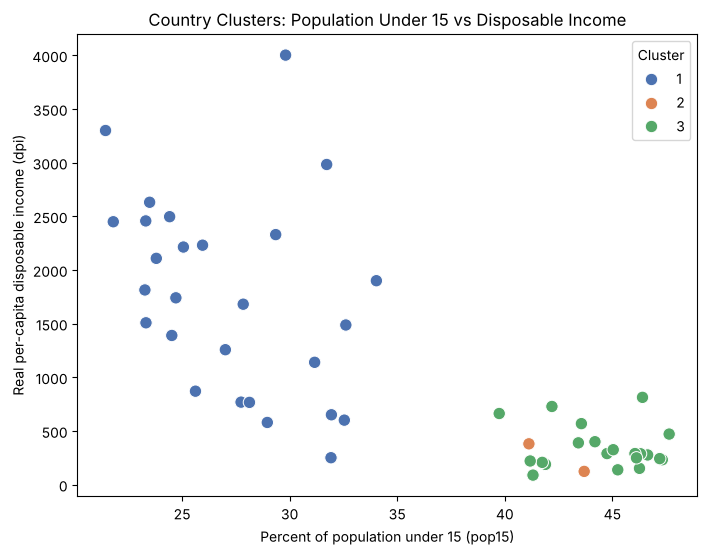

In [6]:
# AI CODE 4: labeled chart of the clusters
# Scatterplot of two variables, colored by cluster
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="pop15", y="dpi", hue="cluster", palette="deep", s=80)
plt.title("Country Clusters: Population Under 15 vs Disposable Income")
plt.xlabel("Percent of population under 15 (pop15)")
plt.ylabel("Real per-capita disposable income (dpi)")
plt.legend(title="Cluster")
plt.show()

## Verification

In [7]:
# Calculate Cluster 1 means using groupby
cluster_means = df.groupby("cluster")[features].mean().round(2)

# Compare Cluster 1 with overall dataset means
overall_means = df[features].mean().round(2)

comparison = pd.DataFrame({
    "Overall Mean": overall_means,
    "Cluster 1 Mean": cluster_means.loc[1]
})

print(comparison)

       Overall Mean  Cluster 1 Mean
sr             9.67           11.60
pop15         35.09           27.24
pop75          2.29            3.31
dpi         1106.76         1763.29
ddpi           3.76            3.79


**Verification Comparison**

I chose Cluster 1, containing 27 countries, to compare its average values with the overall dataset averages.

| Column | Overall Mean | Cluster 1 Mean |
|---|---|---|
| sr | 9.67 | 11.60 |
| pop15 | 35.09 | 27.24 |
| pop75 | 2.29 | 3.31 |
| dpi | 1,106.76 | 1,763.29 |
| ddpi | 3.76 | 3.79 |

**Result:** Match. My pandas calculations confirm Claude's Cluster 1 averages, & they differ from the overall averages, especially in disposable income & the percentage of the population under 15.

## Interpretation and caution

Based on a comparison of the cluster averages with the data for each country in the dataset, I verified Claude’s work was correct. I find Cluster 1 to include those countries with higher per capita incomes, higher savings rates as a percentage of disposable income & smaller proportions of population below age 15; & I find Cluster 3 includes those countries with lower per capita incomes, lower savings rates & larger proportions of population below age 15. The second cluster appears to contain only two countries & can be distinguished from clusters one & three by its relatively large average annual increase in per capita income. I would cautious to accept the full implications of Claude’s findings based upon his application of Hierarchical Clustering since I have not learned about Hierarchical Clustering methods & therefore do not know if Hierarchical Clustering is an appropriate means for grouping countries into clusters.